# Step 1: Data Download and Preparation
We will download the **CIFAR-10** dataset using `torchvision`. This dataset consists of 60,000 32x32 color images in 10 classes, with 50,000 training images and 10,000 test images.

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# Download the training and test sets of CIFAR-10
train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

print(f"Dataset downloaded successfully!")
print(f"Number of training images: {len(train_dataset)}")
print(f"Number of test images: {len(test_dataset)}")

100%|██████████| 170M/170M [08:36<00:00, 330kB/s]


Dataset downloaded successfully!
Number of training images: 50000
Number of test images: 10000


Let's visualize a few sample images from our downloaded dataset to verify everything is loaded correctly.

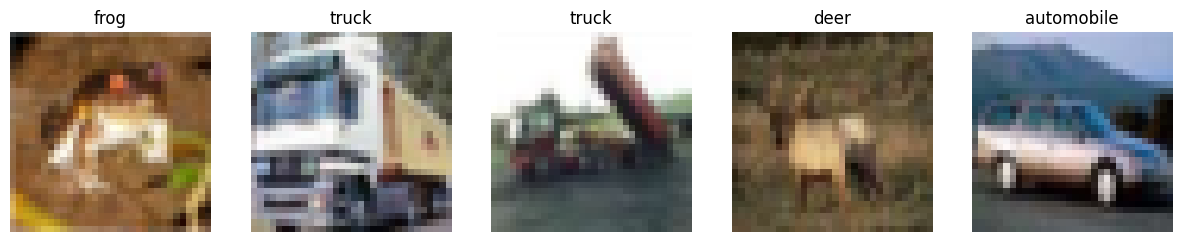

In [2]:
def show_images(dataset, num_images=5):
    classes = dataset.classes
    fig, axes = plt.subplots(1, num_images, figsize=(15, 3))
    for i in range(num_images):
        img, label = dataset[i]
        # Convert tensor to numpy for plotting
        np_img = img.numpy().transpose((1, 2, 0))
        axes[i].imshow(np_img)
        axes[i].set_title(classes[label])
        axes[i].axis('off')
    plt.show()

show_images(train_dataset)

# Step 2: SimCLR Data Augmentation Module
According to the SimCLR paper, we need to create two differently augmented views of each image, forming a positive pair. The sequence consists of:
1. **Random Resized Crop**
2. **Random Horizontal Flip**
3. **Color Jitter** (with strength parameters scaled as described in the paper)
4. **Random Grayscale**
5. **Gaussian Blur** (optional for small images like CIFAR-10, but we will include it for educational completeness)

We will implement a transform wrapper that returns two augmented versions of a single input image.

In [3]:
import random
from PIL import Image, ImageFilter

class GaussianBlur(object):
    """Simple Gaussian Blur transform as specified in the SimCLR paper."""
    def __init__(self, kernel_size, sigma_min=0.1, sigma_max=2.0):
        self.sigma_min = sigma_min
        self.sigma_max = sigma_max
        self.kernel_size = kernel_size

    def __call__(self, img):
        sigma = random.uniform(self.sigma_min, self.sigma_max)
        img = img.filter(ImageFilter.GaussianBlur(radius=sigma))
        return img

class ContrastiveTransformations(object):
    """Generates two random transformations of the same image."""
    def __init__(self, base_transforms):
        self.base_transforms = base_transforms

    def __call__(self, x):
        return [self.base_transforms(x), self.base_transforms(x)]

In [4]:
# SimCLR paper suggests scaling color jitter intensity based on a strength parameter 's'
s = 0.5
color_jitter = transforms.ColorJitter(
    0.8 * s, 0.8 * s, 0.8 * s, 0.2 * s
)

# Construct the SimCLR transform pipeline
simclr_transform = transforms.Compose([
    transforms.RandomResizedCrop(size=32, scale=(0.08, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([color_jitter], p=0.8),
    transforms.RandomGrayscale(p=0.2),
    GaussianBlur(kernel_size=3),
    transforms.ToTensor()
])

# Wrap it to produce positive pairs (two augmented views)
contrastive_transform = ContrastiveTransformations(simclr_transform)

Let's load the dataset again using our new contrastive transform and visualize the positive pairs (two differently augmented views of the same image).

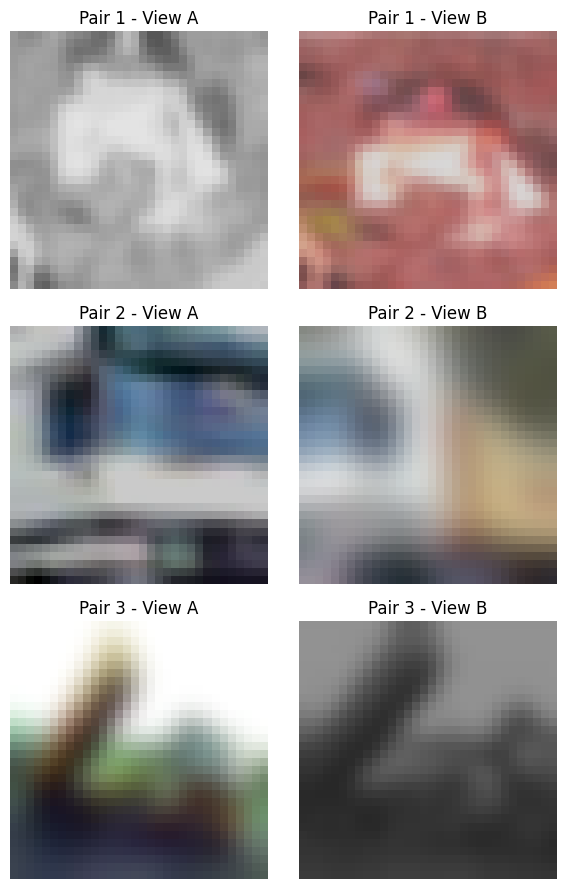

In [5]:
# Load CIFAR-10 with the contrastive transformation
contrastive_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=False,
    transform=contrastive_transform
)

# Helper function to plot positive pairs
def show_contrastive_pairs(dataset, num_pairs=3):
    fig, axes = plt.subplots(num_pairs, 2, figsize=(6, 3 * num_pairs))
    for i in range(num_pairs):
        (img1, img2), _ = dataset[i]

        # Convert tensors to numpy
        np_img1 = img1.numpy().transpose((1, 2, 0))
        np_img2 = img2.numpy().transpose((1, 2, 0))

        axes[i, 0].imshow(np_img1)
        axes[i, 0].set_title(f"Pair {i+1} - View A")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(np_img2)
        axes[i, 1].set_title(f"Pair {i+1} - View B")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

show_contrastive_pairs(contrastive_dataset)

# Step 3: The Base Encoder Network $f(\cdot)$
According to the paper, the base encoder $f(\cdot)$ extracts representation vectors from the augmented images. We adopt the commonly used **ResNet-18** to obtain $h_i = f(\tilde{x}_i) = \text{ResNet}(\tilde{x}_i) \in \mathbb{R}^d$, where $h_i$ is the output vector after the global average pooling layer.

Because CIFAR-10 contains small $32 \times 32$ images, the standard ResNet-18 (designed for $224 \times 224$ ImageNet images) has too many pooling layers and a large initial kernel which downsamples the images too early. We will modify the first convolution layer (`conv1`) and remove the initial `maxpool` layer to preserve features.

In [6]:
import torch.nn as nn
import torchvision.models as models

class SimCLRBaseEncoder(nn.Module):
    def __init__(self, base_model_name='resnet18'):
        super(SimCLRBaseEncoder, self).__init__()

        # Load base model
        if base_model_name == 'resnet18':
            base_model = models.resnet18(weights=None)
        else:
            raise ValueError("Unsupported base model architecture")

        # Retrieve the representation dimension (512 for ResNet18)
        self.feature_dim = base_model.fc.in_features

        # Modify the first conv layer for 32x32 input images
        # (kernel size 3x3, stride 1, padding 1 instead of kernel 7x7, stride 2, padding 3)
        base_model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)

        # Remove the max pooling layer since it reduces the spatial dimensions too fast for 32x32 images
        base_model.maxpool = nn.Identity()

        # Keep all layers except the final fully connected classification layer (fc)
        self.encoder = nn.Sequential(*list(base_model.children())[:-1])

    def forward(self, x):
        # Extract representation h
        h = self.encoder(x)
        # Flatten output from [Batch, 512, 1, 1] to [Batch, 512]
        h = h.view(h.size(0), -1)
        return h

Let's perform a quick sanity check by passing a dummy batch of CIFAR-10 size through our newly defined encoder network to verify the output shapes.

In [7]:
# Instantiate the encoder
encoder = SimCLRBaseEncoder(base_model_name='resnet18')

# Create a dummy batch of 4 augmented images with shape [Batch, Channels, Height, Width]
dummy_input = torch.randn(4, 3, 32, 32)

# Forward pass
with torch.no_grad():
    representation = encoder(dummy_input)

print(f"Input shape: {dummy_input.shape}")
print(f"Representation (h) shape: {representation.shape}")

Input shape: torch.Size([4, 3, 32, 32])
Representation (h) shape: torch.Size([4, 512])


# Step 4: The Projection Head $g(h)$
As specified in the paper, we map the representation vector $h_i$ to a projection $z_i = g(h_i) = W^{(2)} \sigma(W^{(1)} h_i) \in \mathbb{R}^{d'}$, where $\sigma$ is a ReLU activation function. We will implement this as a small MLP with one hidden layer.

In [8]:
import torch
import torch.nn as nn

class ProjectionHead(nn.Module):
    def __init__(self, input_dim=512, hidden_dim=512, output_dim=128):
        super(ProjectionHead, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, h):
        return self.mlp(h)

Let's test this component with a quick sanity check to verify that our features are correctly projected into the 128-dimensional space.

In [9]:
# Instantiate the projection head
projection_head = ProjectionHead(input_dim=512, hidden_dim=512, output_dim=128)

# Map our previous batch representation 'representation' through the head
with torch.no_grad():
    projection = projection_head(representation)

print(f"Representation (h) shape: {representation.shape}")
print(f"Projection (z) shape: {projection.shape}")

Representation (h) shape: torch.Size([4, 512])
Projection (z) shape: torch.Size([4, 128])


# Step 5: The Contrastive Loss Function (NT-Xent)
As specified in Section 2.4 of the paper, the contrastive loss function for a positive pair of augmented examples $(i, j)$ is defined as:

$$\ell_{i,j} = -\log \frac{\exp(\text{sim}(z_i, z_j) / \tau)}{\sum_{k=1}^{2N} \mathbb{1}_{[k \neq i]} \exp(\text{sim}(z_i, z_k) / \tau)}$$

where:
- $\text{sim}(u, v) = \frac{u^T v}{\|u\| \|v\|}$ is the cosine similarity.
- $\tau$ is a temperature parameter (commonly set to 0.5).
- $N$ is the batch size, resulting in $2N$ total views.
- The final loss is computed across all positive pairs in both directions.

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class NTXentLoss(nn.Module):
    def __init__(self, temperature=0.5):
        super(NTXentLoss, self).__init__()
        self.temperature = temperature
        # We use CrossEntropyLoss to compute the loss once we correctly structure our similarities
        self.cross_entropy = nn.CrossEntropyLoss(reduction="mean")

    def forward(self, z_i, z_j):
        """
        z_i: [BatchSize, ProjectionDim] tensor of projections for View A
        z_j: [BatchSize, ProjectionDim] tensor of projections for View B
        """
        batch_size = z_i.shape[0]

        # Normalize projections to calculate cosine similarity via matrix multiplication
        z_i_norm = F.normalize(z_i, dim=1)
        z_j_norm = F.normalize(z_j, dim=1)

        # Concatenate both views to form a [2N, ProjectionDim] tensor
        representations = torch.cat([z_i_norm, z_j_norm], dim=0)

        # Calculate pairwise similarity matrix [2N, 2N]
        similarity_matrix = torch.matmul(representations, representations.T)

        # Scale by temperature
        similarity_matrix = similarity_matrix / self.temperature

        # Create a mask to remove self-similarity calculations (diagonal values)
        # as we do not compare an augmented image with itself
        mask = torch.eye(2 * batch_size, dtype=torch.bool, device=z_i.device)

        # We want to pull out the positive pairs:
        # - For view A_k (index k), the positive pair is view B_k (index k + N)
        # - For view B_k (index k + N), the positive pair is view A_k (index k)
        labels = torch.cat([
            torch.arange(batch_size, 2 * batch_size, device=z_i.device),
            torch.arange(0, batch_size, device=z_i.device)
        ], dim=0)

        # Filter out self-similarity from similarity matrix
        # We can do this by setting self-similarities to a very small number
        similarity_matrix[mask] = -1e9

        # Cross entropy directly minimizes similarity with negatives while maximizing with positive target
        loss = self.cross_entropy(similarity_matrix, labels)
        return loss

Let's perform a quick validation check. We'll generate two mock representation sets ($z_i$ and $z_j$) and verify the NT-Xent loss is correctly computed.

In [11]:
# Instantiate the loss module
criterion = NTXentLoss(temperature=0.5)

# Generate dummy projection matrices for positive pairs (Batch size of 4, projection dim of 128)
z_i = torch.randn(4, 128)
# Make z_j very similar to z_i to simulate a trained model where loss should be low
z_j = z_i + torch.randn(4, 128) * 0.1

loss_low = criterion(z_i, z_j)

# Generate unrelated projections to simulate high loss
z_j_unrelated = torch.randn(4, 128)
loss_high = criterion(z_i, z_j_unrelated)

print(f"Loss with aligned positive pairs (expected lower): {loss_low.item():.4f}")
print(f"Loss with unaligned random pairs (expected higher): {loss_high.item():.4f}")

Loss with aligned positive pairs (expected lower): 0.5657
Loss with unaligned random pairs (expected higher): 1.9577


### Step 6: Setting up the DataLoader and Hardware Accelerator
We will define our hyperparameters, initialize the CUDA/MPS/CPU device, and prepare the training DataLoader using our dual-view `ContrastiveTransformations` pipeline.

In [12]:
from torch.utils.data import DataLoader

# Hyperparameters
batch_size = 256
epochs = 5
learning_rate = 3e-4
weight_decay = 1e-4
temperature = 0.5

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Create Contrastive Training DataLoader
train_loader = DataLoader(
    contrastive_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    drop_last=True
)

Using device: cuda


### Step 7: Defining the Full SimCLR Model and Optimizer
We wrap both the `SimCLRBaseEncoder` and the `ProjectionHead` into a single module so we can pass images directly to obtain representations, then project them to the latent space. We will use the **Adam** optimizer paired with a **CosineAnnealingLR** learning rate scheduler.

In [13]:
class SimCLRModel(nn.Module):
    def __init__(self, base_encoder, projection_head):
        super(SimCLRModel, self).__init__()
        self.encoder = base_encoder
        self.projection_head = projection_head

    def forward(self, x):
        h = self.encoder(x)
        z = self.projection_head(h)
        return z

# Initialize model parts
base_encoder = SimCLRBaseEncoder(base_model_name='resnet18')
projection_head = ProjectionHead(input_dim=512, hidden_dim=512, output_dim=128)
model = SimCLRModel(base_encoder, projection_head).to(device)

# Optimizer and Scheduler
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=0, last_epoch=-1)

# Loss Function
criterion = NTXentLoss(temperature=temperature).to(device)

### Step 8: The Training Loop
We now execute the training loop over the training dataset. For each batch, we perform the contrastive split on our positive pairs ($x_i, x_j$), forward them through our network, compute the NT-Xent loss, update parameters, and step the learning rate scheduler.

In [14]:
import time

print("Starting training loop...")
model.train()

for epoch in range(1, epochs + 1):
    start_time = time.time()
    epoch_loss = 0.0

    for batch_idx, ((img_i, img_j), _) in enumerate(train_loader):
        # Send both augmented views to device
        img_i = img_i.to(device)
        img_j = img_j.to(device)

        # Zero gradients
        optimizer.zero_grad()

        # Forward pass for both augmented views
        z_i = model(img_i)
        z_j = model(img_j)

        # Compute NT-Xent loss
        loss = criterion(z_i, z_j)

        # Backward pass & Optimization
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

        if (batch_idx + 1) % 50 == 0:
            print(f"Epoch [{epoch}/{epochs}], Step [{batch_idx+1}/{len(train_loader)}], Batch Loss: {loss.item():.4f}")

    # Step learning rate scheduler
    scheduler.step()

    avg_loss = epoch_loss / len(train_loader)
    elapsed_time = time.time() - start_time
    print(f"===> Epoch [{epoch}/{epochs}] Completed | Average Loss: {avg_loss:.4f} | Time: {elapsed_time:.2f}s | LR: {scheduler.get_last_lr()[0]:.6f}\n")

Starting training loop...
Epoch [1/5], Step [50/195], Batch Loss: 5.4367
Epoch [1/5], Step [100/195], Batch Loss: 5.3599
Epoch [1/5], Step [150/195], Batch Loss: 5.3357
===> Epoch [1/5] Completed | Average Loss: 5.4393 | Time: 115.27s | LR: 0.000271

Epoch [2/5], Step [50/195], Batch Loss: 5.2871
Epoch [2/5], Step [100/195], Batch Loss: 5.2797
Epoch [2/5], Step [150/195], Batch Loss: 5.2032
===> Epoch [2/5] Completed | Average Loss: 5.2498 | Time: 133.07s | LR: 0.000196

Epoch [3/5], Step [50/195], Batch Loss: 5.2130
Epoch [3/5], Step [100/195], Batch Loss: 5.1636
Epoch [3/5], Step [150/195], Batch Loss: 5.1588
===> Epoch [3/5] Completed | Average Loss: 5.1799 | Time: 132.44s | LR: 0.000104

Epoch [4/5], Step [50/195], Batch Loss: 5.1549
Epoch [4/5], Step [100/195], Batch Loss: 5.1416
Epoch [4/5], Step [150/195], Batch Loss: 5.1171
===> Epoch [4/5] Completed | Average Loss: 5.1345 | Time: 132.17s | LR: 0.000029

Epoch [5/5], Step [50/195], Batch Loss: 5.0792
Epoch [5/5], Step [100/195]